# N11 — Is global normalisation the cause?

N10 refuted the learned dependence idea. Under border only occlusion, with zero data cells hidden,
the classical decoder collapses harder than the neural one (62.5 pp spread against 43.8 pp). Both
decoders have the problem, so it is not something the network acquired in training.

### The remaining explanation

The border ring is 28 of the marker's 64 cells, which is 44 percent of its area. Both decoders
perform a global intensity operation over the whole crop before reading any bit. Classical uses
Otsu thresholding on the full warped marker. Neural uses min max normalisation on the full 64 by 64
crop. Painting 44 percent of the area bright shifts that global statistic, and the real white data
cells stop reading as white relative to the new scale.

Shadow ArUco amplifies this because the room is dark. Median frame brightness is 31 out of 255, so a
white occluder is a very large outlier.

### Four arms

| arm | normalisation | what it isolates |
|---|---|---|
| **published** | min max over the whole occluded crop | the current behaviour |
| **oracle constants** | min and max taken from the clean image, applied to the occluded crop | whether normalisation alone explains the collapse |
| **inner region** | min max over the data region only, ignoring the border | a deployable fix |
| **classical adaptive** | adaptive local thresholding instead of global Otsu | the same fix on the classical side |

The oracle constants arm is the diagnosis. The inner region and adaptive arms are candidate fixes.

**Caveat to keep in mind.** The neural decoder was trained with full crop normalisation. Changing
normalisation at inference is a distribution shift, so absolute numbers move for that reason alone.
The oracle constants arm is least affected, because those are the constants the decoder would have
seen had no occluder been present. Read the oracle arm as the diagnosis and treat the others as
indicative.

No training. Reuses the N10 pipeline.

## 1. Setup

In [1]:
RUN_ON = 'dev'

import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, h5py
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

try:
    from google.colab import drive; drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/aruco_p2'; WORK = '/content/work'
except Exception:
    BASE = os.path.expanduser('~/aruco_p2'); WORK = os.path.join(BASE, 'work')
ART, CACHE = f'{BASE}/artifacts', f'{BASE}/archives'
os.makedirs(WORK, exist_ok=True)

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1',
                    'https://github.com/AVAuco/deeparuco.git', REPO], check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits

def load_weights_safe(p):
    store = {}
    with h5py.File(p,'r') as f:
        root = f['model_weights'] if 'model_weights' in f else f
        def walk(g, pre=''):
            for k in g.keys():
                try: o = g[k]
                except (KeyError, OSError): continue
                q = f'{pre}/{k}'
                if isinstance(o, h5py.Dataset): store[q] = np.array(o)
                elif isinstance(o, h5py.Group): walk(o, q)
        walk(root)
    def pick(l, s):
        h = [k for k in store if f'/{l}/' in k and k.endswith(s)]
        assert len(h)==1, f'{l}:{s} -> {h}'
        return store[h[0]]
    w = {'c1_w':pick('conv2d','kernel:0'),'c1_b':pick('conv2d','bias:0'),'p1_a':pick('p_re_lu','alpha:0'),
         'c2_w':pick('conv2d_1','kernel:0'),'c2_b':pick('conv2d_1','bias:0'),'p2_a':pick('p_re_lu_1','alpha:0'),
         'c3_w':pick('conv2d_2','kernel:0'),'c3_b':pick('conv2d_2','bias:0')}
    for k,s in {'c1_w':(5,5,1,8),'c1_b':(8,),'p1_a':(28,28,8),'c2_w':(3,3,8,4),
                'c2_b':(4,),'p2_a':(12,12,4),'c3_w':(1,1,4,1),'c3_b':(1,)}.items():
        assert w[k].shape==s, f'{k}: {w[k].shape} != {s}'
    return w

splits = json.load(open(f'{ART}/splits.json'))
VIEWS  = splits['dev'] if RUN_ON=='dev' else [splits['heldout'][0]]
STRIDE = splits['benchmark_stride']
Wk  = load_weights_safe(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
print(f'RUN_ON={RUN_ON} views={VIEWS} cv2={cv2.__version__}')

Mounted at /content/drive
RUN_ON=dev views=['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] cv2=5.0.0


## 2. Pipeline, with normalisation made switchable

In [2]:
r_int = lambda v: int(round(v))
CELL, MARGIN = 8, 0.13

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]
def warp(crop, c, t):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))
def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)
def region_masks(corners, shape):
    c = corners.mean(axis=0); inner = c + (corners - c) * (6.0/8.0)
    mo = np.zeros(shape, np.uint8); cv2.fillPoly(mo, [corners.astype(np.int32)], 255)
    mi = np.zeros(shape, np.uint8); cv2.fillPoly(mi, [inner.astype(np.int32)], 255)
    return cv2.bitwise_and(mo, cv2.bitwise_not(mi)), mi
def strip_box(img, corners, level, key, mid):
    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    side = int(np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode())).integers(0,4))
    box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
           (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    return (a,b,c,d) if (c>a and d>b) else None
def make_condition(img, corners, cond, value, key, mid, level=0.50):
    if cond == 'clean': return img
    border, data = region_masks(corners, img.shape[:2])
    if cond == 'border_only':
        paint = border
    else:
        box = strip_box(img, corners, level, key, mid)
        if box is None: return None
        a,b,c,d = box
        strip = np.zeros(img.shape[:2], np.uint8); strip[b:d, a:c] = 255
        paint = cv2.bitwise_and(strip, data) if cond == 'data_only' else strip
    out = img.copy(); out[paint > 0] = int(value)
    return out
def crop64(img, corners):
    """Raw 64x64 crop plus the normalised corner coordinates. No normalisation applied yet."""
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    raw = cv2.resize(img[sl], (64,64)).astype(np.float32)
    nc  = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    return raw, nc

def inner_mask64(nc):
    """Mask of the data region inside the 64x64 crop, used by the inner-region arm."""
    pts = np.array([[nc[0]*63,nc[1]*63],[nc[2]*63,nc[3]*63],
                    [nc[4]*63,nc[5]*63],[nc[6]*63,nc[7]*63]], np.float32)
    c = pts.mean(axis=0); inner = c + (pts - c)*(6.0/8.0)
    m = np.zeros((64,64), np.uint8); cv2.fillPoly(m, [inner.astype(np.int32)], 255)
    return m > 0

def normalise(raw, mode, nc=None, const=None):
    if mode == 'published':
        lo, hi = raw.min(), raw.max()
    elif mode == 'oracle':
        lo, hi = const
    elif mode == 'inner':
        m = inner_mask64(nc)
        lo, hi = (raw[m].min(), raw[m].max()) if m.any() else (raw.min(), raw.max())
    else:
        raise ValueError(mode)
    return np.clip((raw - lo) / (hi - lo + 1e-9), 0.0, 1.0)

def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out
print('pipeline ready')

pipeline ready


## 3. Decoders

In [4]:
def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def neural_probs(x32, chunk=4096):
    out=[]
    for s in range(0,len(x32),chunk):
        x = np.asarray(x32[s:s+chunk],np.float32)[...,None]
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)
def neural_identify(P):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)

def classical_grid(crop_gray, thresh='otsu', n=6, border=1):
    side = (n + 2*border) * CELL
    img = cv2.resize(crop_gray.astype(np.uint8), (side, side), interpolation=cv2.INTER_NEAREST)
    if thresh == 'otsu':
        _, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        blk = max(3, (CELL*2)|1)          # window of about two cells, forced odd
        bw = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, blk, 2)
    g = n + 2*border; m = int(round(CELL*MARGIN))
    out = np.zeros((g, g), np.uint8)
    for r in range(g):
        for c in range(g):
            cell = bw[r*CELL+m:(r+1)*CELL-m, c*CELL+m:(c+1)*CELL-m]
            out[r, c] = 1 if cv2.countNonZero(cell) > cell.size//2 else 0
    return out
def classical_identify(grid):
    obs = grid[1:-1, 1:-1].astype(np.int16).reshape(36)
    best, bid = 99, -1
    for k in range(4):
        d = np.abs(ROT[k].astype(np.int16) - obs).sum(1)
        i = int(d.argmin())
        if d[i] < best: best, bid = int(d[i]), i
    return bid

def render(i, px=200):
    g = np.zeros((8,8), np.uint8); g[1:7,1:7] = CB[i]*255
    return cv2.resize(g, (px,px), interpolation=cv2.INTER_NEAREST)
for th in ('otsu','adaptive'):
    ok = sum(classical_identify(classical_grid(render(i), th)) == i for i in [0,42,100,238,243,249])
    print(f'classical self test, {th}: {ok}/6')
    assert ok == 6, f'{th} thresholding is broken'

classical self test, otsu: 6/6
classical self test, adaptive: 6/6


## 4. Build and evaluate

For every marker the clean crop is built first, so its min and max can serve as the oracle
constants for the occluded versions of that same marker.

In [5]:
CONDS  = ['clean', 'border_only', 'both']
INTENS = [0, 64, 127, 192, 255]
ARMS   = ['published', 'oracle', 'inner']

acc = {(c,v,a): [0,0] for c in CONDS for v in INTENS for a in ARMS}
cls = {(c,v,t): [0,0] for c in CONDS for v in INTENS for t in ('otsu','adaptive')}
rng_stat = {(c,v): [] for c in CONDS for v in INTENS}

BUF = {(c,v,a): [] for c in CONDS for v in INTENS for a in ARMS}
IDS = {(c,v): [] for c in CONDS for v in INTENS}
t0 = time.time()
for vid in VIEWS:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            base, nc = crop64(img, cn)
            if base is None: continue
            const = (base.min(), base.max())           # oracle constants from the clean crop
            for cond in CONDS:
                for v in INTENS:
                    oi = make_condition(img, cn, cond, v, key, mid)
                    if oi is None: continue
                    raw, nc2 = crop64(oi, cn)
                    if raw is None: continue
                    rng_stat[(cond,v)].append(float(raw.max() - raw.min()))
                    IDS[(cond,v)].append(mid)
                    for a in ARMS:
                        BUF[(cond,v,a)].append(warp(normalise(raw, a, nc2, const), nc2, 32))
                    for th in ('otsu','adaptive'):
                        g = classical_grid(warp(raw, nc2, 64), th)
                        cls[(cond,v,th)][0] += int(classical_identify(g) == mid)
                        cls[(cond,v,th)][1] += 1
    print(f'  {vid} ({time.time()-t0:.0f}s)')

for cond in CONDS:
    for v in INTENS:
        ids = np.array(IDS[(cond,v)])
        for a in ARMS:
            X = np.stack(BUF[(cond,v,a)])
            acc[(cond,v,a)] = [int((neural_identify(neural_probs(X)) == ids).sum()), len(ids)]
        BUF[(cond,v,'published')] = BUF[(cond,v,'oracle')] = BUF[(cond,v,'inner')] = None
    print(f'{cond} decoded ({time.time()-t0:.0f}s)')
n = acc[('clean',0,'published')][1]
assert n > 2000, f'only {n} markers'
print(f'\n{n} markers per cell')

  video_1 (116s)
  video_2 (202s)
  video_3 (318s)
  video_4 (427s)
  video_5 (509s)
clean decoded (791s)
border_only decoded (1071s)
both decoded (1350s)

12276 markers per cell


## 5. Results

In [6]:
A = lambda k: acc[k][0]/max(acc[k][1],1)
Cc = lambda k: cls[k][0]/max(cls[k][1],1)

for cond in CONDS:
    print(f'\n=== {cond} ===')
    print(f"{'occ':>5}{'crop range':>12}{'published':>11}{'ORACLE':>9}{'inner':>8}"
          f"{'cls otsu':>10}{'cls adapt':>11}")
    print('-'*66)
    for v in INTENS:
        print(f'{v:>5}{np.mean(rng_stat[(cond,v)]):>12.1f}'
              f'{A((cond,v,"published")):>11.1%}{A((cond,v,"oracle")):>9.1%}'
              f'{A((cond,v,"inner")):>8.1%}{Cc((cond,v,"otsu")):>10.1%}{Cc((cond,v,"adaptive")):>11.1%}')
    for a in ARMS:
        s = [A((cond,v,a)) for v in INTENS]
        print(f'  {a:>10} spread across intensity: {(max(s)-min(s))*100:>5.1f} pp')
    for th in ('otsu','adaptive'):
        s = [Cc((cond,v,th)) for v in INTENS]
        print(f'  classical {th:>8} spread: {(max(s)-min(s))*100:>5.1f} pp')


=== clean ===
  occ  crop range  published   ORACLE   inner  cls otsu  cls adapt
------------------------------------------------------------------
    0       146.0      99.5%    99.5%   99.5%     85.4%      72.3%
   64       146.0      99.5%    99.5%   99.5%     85.4%      72.3%
  127       146.0      99.5%    99.5%   99.5%     85.4%      72.3%
  192       146.0      99.5%    99.5%   99.5%     85.4%      72.3%
  255       146.0      99.5%    99.5%   99.5%     85.4%      72.3%
   published spread across intensity:   0.0 pp
      oracle spread across intensity:   0.0 pp
       inner spread across intensity:   0.0 pp
  classical     otsu spread:   0.0 pp
  classical adaptive spread:   0.0 pp

=== border_only ===
  occ  crop range  published   ORACLE   inner  cls otsu  cls adapt
------------------------------------------------------------------
    0       153.3      92.2%    99.2%   91.3%     72.7%      68.3%
   64       156.5      78.7%    89.8%   78.4%     42.6%      69.7%
  127     

## 6. Verdict

BORDER ONLY, spread across occluder intensity (lower is more robust)
  neural, published normalisation :  43.5 pp
  neural, ORACLE constants        :  24.0 pp
  neural, inner region only       :  42.7 pp
  classical, global Otsu          :  62.4 pp
  classical, adaptive threshold   :  36.4 pp

oracle normalisation removes 45% of the collapse

PARTIAL. Normalisation explains some of the collapse but not most of it.
Report the decomposition rather than a single cause.


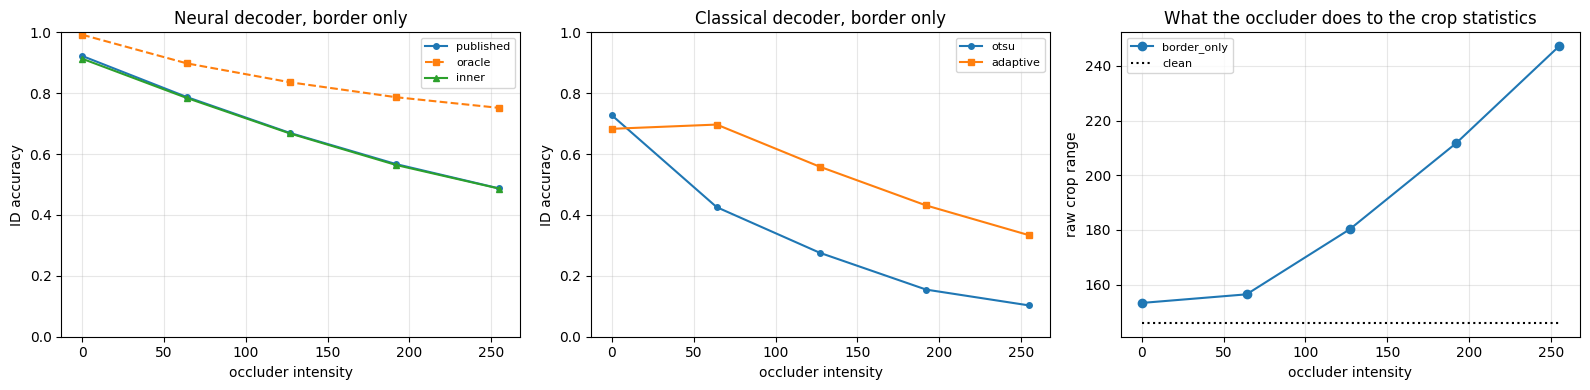


saved -> /content/drive/MyDrive/aruco_p2/artifacts/n11_normalisation_dev.json


In [7]:
sp = lambda a: max(A(('border_only',v,a)) for v in INTENS) - min(A(('border_only',v,a)) for v in INTENS)
spc = lambda t: max(Cc(('border_only',v,t)) for v in INTENS) - min(Cc(('border_only',v,t)) for v in INTENS)

s_pub, s_ora, s_inn = sp('published'), sp('oracle'), sp('inner')
s_ots, s_ada = spc('otsu'), spc('adaptive')

print('BORDER ONLY, spread across occluder intensity (lower is more robust)')
print(f'  neural, published normalisation : {s_pub*100:>5.1f} pp')
print(f'  neural, ORACLE constants        : {s_ora*100:>5.1f} pp')
print(f'  neural, inner region only       : {s_inn*100:>5.1f} pp')
print(f'  classical, global Otsu          : {s_ots*100:>5.1f} pp')
print(f'  classical, adaptive threshold   : {s_ada*100:>5.1f} pp\n')

removed = (s_pub - s_ora)/s_pub*100 if s_pub > 1e-6 else float('nan')
print(f'oracle normalisation removes {removed:.0f}% of the collapse\n')

if s_ora < 0.4*s_pub:
    print('CONFIRMED. Holding the normalisation constants fixed removes most of the collapse.')
    print('The cause is the global intensity normalisation, not the decoder. Any pipeline that')
    print('crops around a marker and normalises over the whole crop inherits this, which is why')
    print('the classical decoder fails too.')
    if s_inn < 0.6*s_pub or s_ada < 0.6*s_ots:
        print('\nA deployable fix works as well: restricting the statistic to the data region')
        print('(neural) or using adaptive thresholding (classical) recovers much of the loss.')
    else:
        print('\nBut the deployable variants do not recover it. Note that the neural decoder was')
        print('trained with full crop normalisation, so the inner-region arm suffers a')
        print('distribution shift; retraining under the new normalisation is the proper test.')
elif s_ora < 0.7*s_pub:
    print('PARTIAL. Normalisation explains some of the collapse but not most of it.')
    print('Report the decomposition rather than a single cause.')
else:
    print('NOT THE CAUSE. Fixing the normalisation constants changes little, so the collapse')
    print('survives even when the occluder cannot affect the global statistic. Look elsewhere.')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, st in [('published','-o'), ('oracle','--s'), ('inner','-^')]:
    ax[0].plot(INTENS, [A(('border_only',v,a)) for v in INTENS], st, ms=4, label=a)
ax[0].set_title('Neural decoder, border only'); ax[0].legend(fontsize=8)
for t, st in [('otsu','-o'), ('adaptive','-s')]:
    ax[1].plot(INTENS, [Cc(('border_only',v,t)) for v in INTENS], st, ms=4, label=t)
ax[1].set_title('Classical decoder, border only'); ax[1].legend(fontsize=8)
ax[2].plot(INTENS, [np.mean(rng_stat[('border_only',v)]) for v in INTENS], '-o', label='border_only')
ax[2].plot(INTENS, [np.mean(rng_stat[('clean',v)]) for v in INTENS], 'k:', label='clean')
ax[2].set_ylabel('raw crop range'); ax[2].set_title('What the occluder does to the crop statistics')
ax[2].legend(fontsize=8)
for a in ax[:2]:
    a.set_ylabel('ID accuracy'); a.set_ylim(0,1)
for a in ax:
    a.set_xlabel('occluder intensity'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

json.dump({'run_on':RUN_ON,'views':VIEWS,'n_markers':int(n),'intensities':INTENS,
           'neural':{f'{c}_{v}_{a}':A((c,v,a)) for c in CONDS for v in INTENS for a in ARMS},
           'classical':{f'{c}_{v}_{t}':Cc((c,v,t)) for c in CONDS for v in INTENS
                        for t in ('otsu','adaptive')},
           'crop_range':{f'{c}_{v}':float(np.mean(rng_stat[(c,v)])) for c in CONDS for v in INTENS},
           'border_only_spread':{'published':float(s_pub),'oracle':float(s_ora),'inner':float(s_inn),
                                 'otsu':float(s_ots),'adaptive':float(s_ada)},
           'pct_removed_by_oracle':float(removed)},
          open(f'{ART}/n11_normalisation_{RUN_ON}.json','w'), indent=1)
print(f'\nsaved -> {ART}/n11_normalisation_{RUN_ON}.json')